# 10. 注意力机制  

主要内容：
- 1. 1964年的Nadaraya-Waston核回归（kernel regression）正是具有 注意力机制（attention mechanism）的机器学习的简单演示

- 2. 注意力函数：如何使用这些函数来设计Bahdanau注意力。Bahdanau注意力是深度学习中的具有突破性价值的注意力模型，它双向对齐并且可以微分。

- 3. 仅仅基于注意力机制的Transformer架构， 该架构中使用了多头注意力（multi-head attention） 和自注意力（self-attention）。 自2017年横空出世，Transformer一直都普遍存在于现代的深度学习应用中， 例如语言、视觉、语音和强化学习领域。


## 10.1 注意力提示 


### 10.1.1. 生物学中的注意力提示  

自主性注意力：人类主动调用起来的注意力  
非自住性注意力：人类被动吸引起来的注意力


### 10.1.2. 查询、键和值  
在注意力机制的背景下， 自主性提示被称为查询（query）。给定任何查询，注意力机制通过注意力汇聚（attention pooling） 将选择引导至感官输入（sensory inputs，例如中间特征表示）。 在注意力机制中，这些感官输入被称为值（value）。 更通俗的解释，每个值都与一个键（key）配对， 这可以想象为感官输入的非自主提示。 如 图10.1.3所示，可以通过设计注意力汇聚的方式， 便于给定的查询（自主性提示）与键（非自主性提示）进行匹配， 这将引导得出最匹配的值（感官输入）。

注意力机制通过注意力汇聚将查询（自主性提示）和键（非自主性提示）结合在一起，实现对值（感官输入）的选择倾向
![image.png](img/chapter10-focus.png)


### 10.1.3. 注意力的可视化  


In [1]:
import torch
from d2l import torch as d2l

f:\code\condaEnv\py310\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
#@save
def show_heatmaps(matrices, xlabel, ylabel, titles=None, figsize=(2.5, 2.5), cmap = 'Reds'):
    """show matrix heatmaps"""
    d2l.use_svg_display()
    num_rows, num_cols = matrices.shape[0], matrices.shape[1]
    fig, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize, squeeze=False)
    for i, (row_axes, row_matrices) in enumerate(zip(axes, matrices)):
        for j, (ax, matrix) in enumerate(zip(row_axes, row_matrices)):
            pcm = ax.imshow(matrix.detach().numpy(), cmap=cmap)
            if i == num_rows - 1:
                ax.set_xlabel(xlabel)
            if j == 0:
                ax.set_ylabel(ylabel)
            if titles:
                ax.set_title(titles[j])
    fig.colorbar(pcm, ax=axes, shrink=0.6)

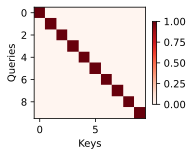

In [3]:
attention_weights = torch.eye(10).reshape((1, 1, 10, 10))
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')

## 10.2 注意力汇聚：Nadaraya-Watson 核回归


In [4]:
import math
import torch
from torch import nn
from d2l import torch as d2l

### 10.2.1 生成数据集

使用一个非线性函数生成一个人工数据集

In [5]:
n_train = 50 # 训练样本数
x_train, _ = torch.sort(torch.rand(n_train) * 5) # 排序后的训练样本

def f(x):
    return 2 * torch.sin(x) + x ** 0.8  

y_train = f(x_train) + torch.normal(0.0, 0.5, (n_train,)) # 训练样本的标签
x_test = torch.arange(0, 5, 0.1) # 测试样本
y_truth = f(x_test) # 测试样本的真实输出
n_test = len(x_test) # 测试样本数
n_test
    

50

In [6]:
def plot_kernel_reg(y_hat):
    d2l.plot(x_test, [y_truth, y_hat], 'x', 'y', legend=['Truth', 'Pred'], xlim=[0, 5], ylim=[-1, 5])
    d2l.plt.plot(x_train, y_train, 'o', alpha=0.5)

### 

### 10.2.2 平均汇聚  
  
先使用最简单的估计器来解决回归问题。 基于平均汇聚来计算所有训练样本输出值的平均值：

$$f(x) = \frac{1}{n}\sum_{i=1}^n y_i$$

如下图所示，这个估计器确实不够聪明，真实函数f("Truth")和预测函数（“Pred”）相差很大。  
原因：完全不看 Query(即输入$x_i$)，直接计算所有 $y_i$ 的平均值。 Value 的权重完全相同，因此它不是根据 Query 动态分配权重的。

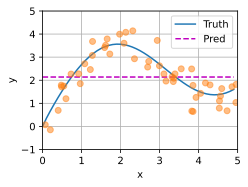

In [7]:
y_hat = torch.repeat_interleave(y_train.mean(), n_test)
plot_kernel_reg(y_hat)

### 10.2.3. 非参数注意力汇聚

平均汇聚忽略了输入$x_i$，更合理的方法是根据距离分配权重：  
Key 离 Query 越近，权重越大；  
Key 离 Query 越远，权重越小。  
采用根据输入的位置对输出$y_i$进行加权的方法：
$$f(x) = \sum_{i=1}^n \frac{K(x - x_i)}{\sum_{j=1}^n K(x - x_j)} y_i$$

上面这个公式名为Nadaraya-Watson核回归（Nadaraya-Watson kernel regression）。Nadaraya-Watson核回归是一个非参数模型。   
***K***是核（kernel,此处采用高斯核（这里省略了根号2Π分之一））：  

$$
K(x-x_i)=\exp\left(-\frac{(x-x_i)^2}{2}\right)
$$

 

于是预测结果为：
$$
\hat y=
\frac{\sum_iK(x-x_i)y_i}
{\sum_jK(x-x_j)}
$$ 
把权重单独写出来：  
$$
\alpha_i=
\frac{\exp\left(-\frac{(x-x_i)^2}{2}\right)}
{\sum_j\exp\left(-\frac{(x-x_j)^2}{2}\right)}
$$  
应该能看出，这其实就是 softmax：  
$$
\alpha_i=
\operatorname{softmax}
\left(-\frac{(x-x_i)^2}{2}\right)
$$  
最终：  
$$
\boxed{
\hat y=\sum_i\alpha_i y_i
}
$$  
这正是注意力机制的标准结构。  



注：  
 高斯核**指数**部分可以视为注意力评分函数（attention scoring function）， 简称评分函数（scoring function）。  高斯核： 
$$  
K(u) = \frac{1}{\sqrt{2\pi}} \exp(-\frac{u^2}{2})
$$  

其中评分函数 $-\frac{(x-x_i)^2}{2}$ ，前面带有负号，  
距离越小，分数越接近0，；距离越大，分数越负。经过指数函数：
$$
e^0 > e^{-0.5} \gg e^{-8}
$$  
因此附近的 Key 得到更大的注意力权重。

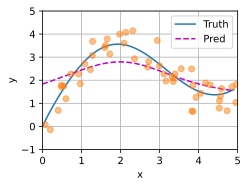

In [8]:
# X_repeat 的形状：（n_test, n_train）,
# 每一行都包含着相同的测试输入（例如：同样的查询）
X_repeat = x_test.repeat_interleave(n_train).reshape((-1, n_train))
# x_train 包含着键。attention_weights 的形状：（n_test, n_train），
# 每一行都包含着要在给定的每个查询的值（y_train）之间分配的注意力权重

attention_weights = nn.functional.softmax(-(X_repeat - x_train) ** 2 / 2, dim=1)
#y_hat 的每个元素都是值的加权平均值， 其中的权重是注意力权重
y_hat = torch.matmul(attention_weights, y_train)
plot_kernel_reg(y_hat)

注意力的权重

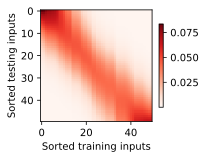

In [9]:
d2l.show_heatmaps(attention_weights.unsqueeze(0).unsqueeze(0), xlabel='Sorted training inputs', ylabel='Sorted testing inputs')

### 10.2.4 带参数注意力汇聚  
非参数的Nadaraya-Watson核回归具有一致性（consistency）的优点：如果有足够多的数据，此模型会收敛到最优结果。  
接下来将可学习参数集成到注意力汇聚中。    


参数 w 控制注意力范围：  
w 较大：距离被放大，注意力更集中，只参考很近的点；  
w 较小：距离差异被缩小，注意力更平缓，会参考更多点。    
  
模型通过训练自动决定应该“看多大范围”。  
这就是从非参数模型到可训练注意力模型的第一步。  


In [10]:
# define model
class NWKernelRegression(nn.Module):
    def __init__(self, **kwargs):
        super().__init__(**kwargs) # 调用父类的构造函数
        self.w = nn.Parameter(torch.rand((1, ), requires_grad = True))

    def forward(self, queries, keys, values):
        # queries 和 attention_weights 的形状为（查询个数，“键-值”对个数）
        queries = queries.repeat_interleave(keys.shape[1]).reshape((-1, keys.shape[1]))
        self.attention_weights = nn.functional.softmax(-((queries - keys)*self.w)**2 / 2, dim=1)
        #values 的形状为（查询个数，“键-值”对个数）
        return torch.bmm(self.attention_weights.unsqueeze(1), values.unsqueeze(-1)).reshape(-1)

In [11]:
# X_tile的形状:(n_train，n_train)，每一行都包含着相同的训练输入
X_tile = x_train.repeat((n_train, 1))
print(X_tile.shape)

# Y_tile的形状:(n_train，n_train)，每一行都包含着相同的训练输出
Y_tile = y_train.repeat((n_train, 1))  
print(Y_tile.shape)

# keys的形状:('n_train'，'n_train'-1)
keys = X_tile[(1 - torch.eye(n_train)).type(torch.bool)].reshape((n_train, -1))
print(keys.shape)

# values的形状:('n_train'，'n_train'-1)
values = Y_tile[(1 - torch.eye(n_train)).type(torch.bool)].reshape((n_train, -1))
print(values.shape)

torch.Size([50, 50])
torch.Size([50, 50])
torch.Size([50, 49])
torch.Size([50, 49])


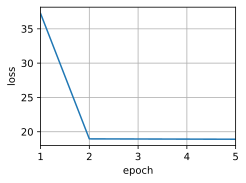

In [12]:
net = NWKernelRegression()
loss = nn.MSELoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.5)
animator = d2l.Animator(xlabel='epoch', ylabel='loss', xlim=[1, 5])

for epoch in range(5):
    trainer.zero_grad()
    l = loss(net(x_train, keys, values), y_train)
    l.sum().backward()
    trainer.step()
    print(f'epoch {epoch + 1}, loss {float(l.sum()):.6f}')
    animator.add(epoch + 1, float(l.sum()))

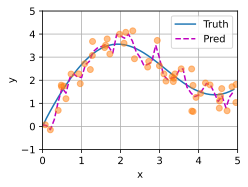

In [13]:
# keys的形状:(n_test，n_train)，每一行包含着相同的训练输入（例如，相同的键）
keys = x_train.repeat((n_test, 1))
# value的形状:(n_test，n_train)
values = y_train.repeat((n_test, 1))
y_hat = net(x_test, keys, values).unsqueeze(1).detach()
plot_kernel_reg(y_hat)



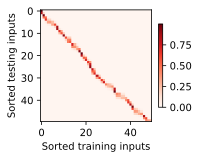

In [14]:
d2l.show_heatmaps(net.attention_weights.unsqueeze(0).unsqueeze(0),
                  xlabel='Sorted training inputs',
                  ylabel='Sorted testing inputs')

本节最重要的一些知识点：    
对照 Q、K、V  
核回归就是一个最简单的一维注意力模型：  
注意力概念|核回归中的对象
---------|----------------
Query|	要预测的位置 $x$
Key	|训练样本的位置 $x_i$
Value	|训练样本的标签 $y_i$
Score	|$-\frac12(x-x_i)^2$
Weight	|对 Score 做 softmax
Output	|$\sum_i\alpha_i y_i$


这张对应表是本节最重要的内容。  
其中：  
$x_i$：第 $i$ 个训练样本的输入；  
$y_i$：第 $i$ 个训练样本的输出；  
$x$：现在需要预测的新输入。  


总结：  
Nadaraya-Watson 核回归并不是与 Transformer 无关的古老公式，它与tranformer 的softmax有相同骨架。

## 10.3 注意力评分

### 10.3.1 掩蔽softmax操作（masked softmax operation）

注意力评分函数：  
$$
a(q,k_i)=-\frac12(q-k_i)^2
$$

但这个公式只能处理非常简单的一维距离。真实模型中的 Query 和 Key 都是向量，因此需要更通用的评分方法。

掩蔽 softmax：由于一个批次中的句子长度通常不同，为了组成同一个张量，需要将较短的句子补齐，补齐后的形状相同了，但 <pad> 不包含任何真实信息。如果直接计算 softmax，模型可能会错误地给 <pad> 分配注意力。于是需要在 softmax 前把填充的这个位置的评分替换成一个极小的数。

valid_lens 表示每个序列的有效长度：valid_lens = torch.tensor([2, 3])表示：  
第一个样本：前2个位置有效  
第二个样本：前3个位置有效

In [15]:
#@save
def masked_softmax(X, valid_lens):
    """通过在最后一个轴上掩蔽元素来执行softmax操作"""
    # X:3D张量，valid_lens:1D或2D张量
    if valid_lens is None:
        return nn.functional.softmax(X, dim=-1)
    else:
        shape = X.shape
        if valid_lens.dim() == 1:
            valid_lens = torch.repeat_interleave(valid_lens, shape[1])
        else:
            valid_lens = valid_lens.reshape(-1)
        # 最后一轴上被掩蔽的元素使用一个非常大的负值替换，从而其softmax输出为0
        X = d2l.sequence_mask(X.reshape(-1, shape[-1]), valid_lens,
                              value=-1e6)
        return nn.functional.softmax(X.reshape(shape), dim=-1)

In [16]:
masked_softmax(torch.rand(2, 2, 4), torch.tensor([2, 3])) #两个2*4矩阵表示的样本， 这两个样本的有效长度分别为2和3。

tensor([[[0.6626, 0.3374, 0.0000, 0.0000],
         [0.6561, 0.3439, 0.0000, 0.0000]],

        [[0.3873, 0.2396, 0.3731, 0.0000],
         [0.2485, 0.4094, 0.3420, 0.0000]]])

解析：  
X = torch.rand(2, 2, 4) — 形状 (batch_size=2, num_heads=2, seq_len=4)

可以理解为：2 个样本，每个样本有 2 个注意力头，每个头对 4 个位置计算了注意力分数（随机值）。

In [17]:
#也可以使用二维张量，为矩阵样本中的每一行指定有效长度。
masked_softmax(torch.rand(2, 2, 4), torch.tensor([[1, 3], [2, 4]]))

tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3306, 0.3615, 0.3080, 0.0000]],

        [[0.5321, 0.4679, 0.0000, 0.0000],
         [0.2352, 0.2622, 0.1984, 0.3042]]])

### 10.3.2 加性注意力（additive attention）

一般来说，当查询和键是不同长度的矢量时，可以使用加性注意力作为评分函数。

上一节核回归使用的评分函数是 $a(q,k) = -1/2(q-k)^2$，它通过距离衡量 Query 和 Key 的相似性，但真实任务中的 Query 和 Key 通常是向量，而且维度可能不同。  
  
加性注意力的解决办法是：
- 先把 Query 和 Key 变换到相同的隐藏空间，再让神经网络学习如何计算匹配程度。

加性注意力（additive attention）的评分函数为：  
$$
a(\mathbf q, \mathbf k) = \mathbf w_v^\top \text{tanh}(\mathbf W_q\mathbf q + \mathbf W_k \mathbf k) \in \mathbb{R}  
$$

第一步：变换 Query  
$$
\mathbf q'=\mathbf W_q\mathbf q
$$  
假设原 Query 有20维，将其变换成8维：
$$
\mathbb R^{20}\rightarrow\mathbb R^8
$$  
第二步：变换 Key
$$
\mathbf k'=\mathbf W_k\mathbf k
$$  
假设原 Key 有30维，也将其变换成8维：
$$
\mathbb R^{30}\rightarrow\mathbb R^8
$$  
Query 和 Key 原本维度不同，但经过两个不同的线性层后，都变成8维，因此可以相加。  
现在 $\mathbf q'$ 和 $\mathbf k'$ 维度相同，可以相加：
$$
\mathbf q'+\mathbf k'\in\mathbb R^8
$$  
这里的8称为隐藏单元数 h，它是人为设置的超参数。  
第三步：经过 tanh  
$$
\mathbf z=\tanh(\mathbf q'+\mathbf k')
$$  
tanh 对向量中的每个数字分别处理，并加入非线性：  
$$
\tanh:\mathbb R\rightarrow(-1,1)
$$  
如果没有非线性，连续的线性变换最终仍然只能表达线性关系。  
第四步：得到一个评分  
目前 $\mathbf z$ 还是8维向量，但一对 Query–Key 最终只需要一个匹配分数，因此使用 $\mathbf w_v$ 把它压缩成标量：  
$$
s=\mathbf w_v^\top\mathbf z\in\mathbb R
$$

之所以叫“加性注意力”，就是因为其中包含：
$$
\mathbf W_q\mathbf q+\mathbf W_k\mathbf k
$$  

核回归的评分规则由人规定,加性注意力的评分规则由模型学习，$\mathbf W_q,\quad\mathbf W_k,\quad\mathbf w_v$ ，都是可学习参数。训练过程中，反向传播会不断调整它们，让相关的 Query 和 Key 获得更高评分。

In [18]:
#@save
class AdditiveAttention(nn.Module):
    """加性注意力"""
    def __init__(self, key_size, query_size, num_hiddens, dropout, **kwargs):
        super(AdditiveAttention, self).__init__(**kwargs)
        self.W_k = nn.Linear(key_size, num_hiddens, bias=False)
        self.W_q = nn.Linear(query_size, num_hiddens, bias=False)
        self.w_v = nn.Linear(num_hiddens, 1, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, queries, keys, values, valid_lens):
        queries, keys = self.W_q(queries), self.W_k(keys)
        # 在维度扩展后，
        # queries的形状：(batch_size，查询的个数，1，num_hidden)
        # key的形状：(batch_size，1，“键－值”对的个数，num_hiddens)
        # 使用广播方式进行求和
        features = queries.unsqueeze(2) + keys.unsqueeze(1)
        features = torch.tanh(features)
        # self.w_v仅有一个输出，因此从形状中移除最后那个维度。
        # scores的形状：(batch_size，查询的个数，“键-值”对的个数)
        scores = self.w_v(features).squeeze(-1)
        self.attention_weights = masked_softmax(scores, valid_lens)
        # values的形状：(batch_size，“键－值”对的个数，值的维度)
        return torch.bmm(self.dropout(self.attention_weights), values)

解析：  
- 对于每一对 Query–Key，我们最终需要的是一个标量评分，这个评分表示这个Key与当前Query到底有多匹配？ 

>经过前面的计算：   
>$$
z=\tanh(W_qq+W_kk)
$$   
>得到的是一个8维隐藏特征：  
>$$
z=[z_1,z_2,\ldots,z_8]
$$
  
>这8个数可以理解为模型从8个隐藏角度描述这对 Query–Key 的关系，但它们还不是一个最终匹配分数。
>于是使用可学习向量：
>$$
w_v=[w_1,w_2,\ldots,w_8]
$$
>进行加权求和：
>$$
s=w_v^\top z
=w_1z_1+w_2z_2+\cdots+w_8z_8
$$
>最终得到一个标量






- w_v：把每对 Query–Key 的8维关系特征变成一个评分；
- squeeze(-1)：移除最后那个大小为1的冗余维度。

In [19]:
queries, keys = torch.normal(0, 1, (2, 1, 20)), torch.ones((2, 10, 2))
# values的小批量，两个值矩阵是相同的
values = torch.arange(40, dtype=torch.float32).reshape(1, 10, 4).repeat(
    2, 1, 1)
valid_lens = torch.tensor([2, 6])

attention = AdditiveAttention(key_size=2, query_size=20, num_hiddens=8,
                              dropout=0.1)
attention.eval()
attention(queries, keys, values, valid_lens)

tensor([[[ 2.0000,  3.0000,  4.0000,  5.0000]],

        [[10.0000, 11.0000, 12.0000, 13.0000]]], grad_fn=<BmmBackward0>)

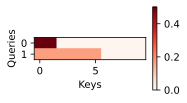

In [20]:
d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')

### 10.3.3. 缩放点积注意力  

加性注意力通过一个小型神经网络计算评分。  
另一种更简单、更高效的方法是直接计算 Query 和 Key 的点积。  
Transformer 使用的就是缩放点积注意力。

缩放点积注意力（scaled dot-product attention）评分函数为：  
$$
a(\mathbf q, \mathbf k) = \mathbf{q}^\top \mathbf{k}  /\sqrt{d}  
$$

缩放点积注意力:

$$  
\mathrm{softmax}\left(\frac{\mathbf Q \mathbf K^\top }{\sqrt{d}}\right) \mathbf V \in \mathbb{R}^{n\times v}
$$

解析：  
1. 为什么叫“缩放”点积？   
评分函数是：  
$$
\boxed{
a(q,k)=\frac{q^\top k}{\sqrt d}
}
$$  
它并不是只计算 $q^\top k$，还要除以：
$$
\sqrt d
$$这里的 \(d\) 是 Query 和 Key 的维度。  
2. 为什么除以 $\sqrt d$？  
向量维度越大，点积就会累加越多项：  
$$
q^\top k
=q_1k_1+q_2k_2+\cdots+q_dk_d
$$  
当 d 很大时，点积的绝对值通常也会变大。  
例如某次得到评分： 
$$
[10,0,-10]
$$  
softmax 后大约是：  
$$
[0.99995,0.00005,0]
$$  
分布几乎变成了“只选择第一个 Key”。此时 softmax 进入饱和区域，梯度会变得很小，训练更加困难。  
如果 $d=100$，则：  
$$
\sqrt d=10
$$  
缩放以后：  
$$
[10,0,-10]\div10=[1,0,-1]
$$  
softmax 后约为：  
$$
[0.665,0.245,0.090]
$$  
它仍然更关注第一个 Key，但没有过早变得极端。  

3. 多个 Queries 和 Keys 如何一起计算？  
假设有：  
3个 Queries；  
4个 Keys；  
每个 Query、Key 都是8维。  
那么：  
$$
Q\in\mathbb R^{3\times8}
$$
$$
K\in\mathbb R^{4\times8}
$$
转置 $K$：  
$$
K^\top\in\mathbb R^{8\times4}
$$  
进行矩阵乘法：
$$
QK^\top:
(3,8)\times(8,4)\rightarrow(3,4)
$$  
得到：
$$
QK^\top=
\begin{bmatrix}
q_1^\top k_1&q_1^\top k_2&q_1^\top k_3&q_1^\top k_4\\
q_2^\top k_1&q_2^\top k_2&q_2^\top k_3&q_2^\top k_4\\
q_3^\top k_1&q_3^\top k_2&q_3^\top k_3&q_3^\top k_4
\end{bmatrix}
$$  
这张 $3\times4$ 的表表示：  
每一行对应一个 Query；  
每一列对应一个 Key；  
每个元素是对应 Query–Key 的匹配评分。  
随后对每行的4个 Keys 做 softmax。  

In [21]:
#@save
class DotProductAttention(nn.Module):
    """缩放点积注意力"""
    def __init__(self, dropout, **kwargs):
        super(DotProductAttention, self).__init__(**kwargs)
        self.dropout = nn.Dropout(dropout)

    # queries的形状：(batch_size，查询的个数，d)
    # keys的形状：(batch_size，“键－值”对的个数，d)
    # values的形状：(batch_size，“键－值”对的个数，值的维度)
    # valid_lens的形状:(batch_size，)或者(batch_size，查询的个数)
    def forward(self, queries, keys, values, valid_lens=None):
        d = queries.shape[-1]
        # 设置transpose_b=True为了交换keys的最后两个维度
        scores = torch.bmm(queries, keys.transpose(1,2)) / math.sqrt(d)
        self.attention_weights = masked_softmax(scores, valid_lens)
        return torch.bmm(self.dropout(self.attention_weights), values)

In [22]:
queries = torch.normal(0, 1, (2, 1, 2))
attention = DotProductAttention(dropout=0.5)
attention.eval()
attention(queries, keys, values, valid_lens)

tensor([[[ 2.0000,  3.0000,  4.0000,  5.0000]],

        [[10.0000, 11.0000, 12.0000, 13.0000]]])

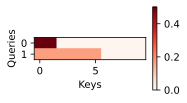

In [23]:
d2l.show_heatmaps(attention.attention_weights.reshape((1, 1, 2, 10)),
                  xlabel='Keys', ylabel='Queries')



### 10.3.4. 小结
将注意力汇聚的输出计算可以作为值的加权平均，选择不同的注意力评分函数会带来不同的注意力汇聚操作。  

当查询和键是不同长度的矢量时，可以使用可加性注意力评分函数。当它们的长度相同时，使用缩放的“点－积”注意力评分函数的计算效率更高。

加性注意力与点积注意力
特点	|加性注意力|	缩放点积注意力
--------|------------|-----------------
Query、Key原始维度	|可以不同|	点积时必须相同
评分方式	|小型神经网络|	向量点积
可学习评分参数	|$W_q,W_k,w_v$	|评分本身没有额外参数
计算效率	|相对较低	|矩阵运算效率高
Transformer中使用|	通常不用|	核心方法


这里说点积评分“没有额外参数”，不代表完整 Transformer 没有参数。Transformer 会先用可学习矩阵生成 $Q、K、V$。